# Evidencia 1 — Construcción y exploración del corpus de letras

**Proyecto:** SONORA · **Materia:** Procesamiento de Lenguaje Natural · **Requisitos:** E1-01 … E1-05 (`docs/REQUIREMENTS.md` v1.2)

**Universo de este notebook:** el corpus **completo** preparado en la ejecución `lyrics_full_v1`
(10 Parquet de Genius, 3 179 588 registros de origen → 3 155 772 letras canónicas en inglés).
Todas las tablas y figuras se calculan sobre ese universo salvo que una celda declare
explícitamente una **muestra** (sólo para ejemplos legibles o auditorías).

El procesamiento pesado no se repite aquí: se ejecutó con los pipelines versionados y este notebook
lee sus salidas.

| Etapa | Comando | Documentación |
|---|---|---|
| Ingesta, limpieza, idioma, duplicados, split | `pipelines/ingestion/prepare_lyrics_corpus.py all --run-id lyrics_full_v1` | `docs/CORPUS_LETRAS.md` |
| Léxico y anotación spaCy | `pipelines/nlp/annotate_corpus.py lexicon` / `annotate` | `config/nlp_annotation.yaml` |
| Estadísticas por letra | `pipelines/nlp/corpus_stats.py` | `packages/sonora/src/sonora/nlp/doc_stats.py` |

In [1]:
import json, sys, textwrap
from pathlib import Path
import numpy as np
import pyarrow as pa, pyarrow.compute as pc, pyarrow.dataset as ds, pyarrow.parquet as pq
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "packages" / "sonora" / "src"))
from sonora import viz
from sonora.preprocessing.lyrics_text import build_views
viz.apply_style()

RUN = "lyrics_full_v1"
P = {
    "manifest": ROOT / "manifests/runs" / f"{RUN}.json",
    "report": ROOT / "reports/corpus" / RUN / "quality_report.json",
    "sources": ROOT / "manifests/sources/genius_snapshot.json",
    "records": ROOT / "data/interim/lyrics" / RUN / "records",
    "corpus": ROOT / "data/processed/lyrics" / RUN / "corpus",
    "mapping": ROOT / "data/processed/lyrics" / RUN / "source_to_lyrics.parquet",
    "exclusions": ROOT / "data/processed/lyrics" / RUN / "exclusions.parquet",
    "splits": ROOT / "data/processed/splits" / RUN / "lyrics_splits.parquet",
    "lexicon": ROOT / "data/processed/nlp" / RUN / "lexicon/lexicon.parquet",
    "gdrop": ROOT / "data/processed/nlp" / RUN / "lexicon/gdrop_forms.parquet",
    "doc_stats": ROOT / "data/processed/nlp" / RUN / "doc_stats",
    "annotation": ROOT / "data/processed/nlp" / RUN / "spacy_sm_v1",
}
FIG = ROOT / "reports/figures/E1"
manifest = json.loads(P["manifest"].read_text(encoding="utf-8"))
report = json.loads(P["report"].read_text(encoding="utf-8"))
print("Ejecución:", manifest["run_id"], "| corpus completo:", manifest["complete_full_corpus_run"],
      "| reconciliado:", report["reconciled"])

def fmt(n):
    return f"{n:,}".replace(",", " ")

def show(rows, cols=None):
    from IPython.display import Markdown, display
    cols = cols or list(rows[0].keys())
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for r in rows:
        lines.append("| " + " | ".join(fmt(r[c]) if isinstance(r[c], (int, np.integer)) else str(r[c]) for c in cols) + " |")
    display(Markdown("\n".join(lines)))

Ejecución: lyrics_full_v1 | corpus completo: True | reconciliado: True


## 1. Fuente, procedencia y esquema (E1-01)

Fuente: dataset de Hugging Face `theelderemo/genius-lyrics-cleaned`, copia local de 10 Parquet.
La revisión del dataset no quedó registrada en la descarga; la identidad exacta de la entrada se
fija por **sha256** de cada archivo. No existe columna de idioma ni identificador único: cada
registro se identifica por `archivo#row=<fila global base 0>`.

In [2]:
snap = json.loads(P["sources"].read_text(encoding="utf-8"))
show([{"archivo": f["name"], "filas": f["num_rows"], "MB": round(f["bytes"] / 1e6, 1),
       "row groups": f["num_row_groups"], "sha256 (12)": f["sha256"][:12]} for f in snap["files"]])
print("Total de filas:", fmt(sum(f["num_rows"] for f in snap["files"])))
print("Esquema:", snap["files"][0]["columns"])

| archivo | filas | MB | row groups | sha256 (12) |
|---|---|---|---|---|
| train-00000-of-00010.parquet | 317 959 | 326.1 | 318 | a6a573dc7640 |
| train-00001-of-00010.parquet | 317 959 | 279.1 | 318 | e46820fbae4b |
| train-00002-of-00010.parquet | 317 959 | 258.3 | 318 | 5027958c0374 |
| train-00003-of-00010.parquet | 317 959 | 244.9 | 318 | 2f13f71bcf21 |
| train-00004-of-00010.parquet | 317 959 | 241.2 | 318 | 6bb939305655 |
| train-00005-of-00010.parquet | 317 959 | 248.2 | 318 | d3eac2425448 |
| train-00006-of-00010.parquet | 317 959 | 251.5 | 318 | ce6cce8e23ae |
| train-00007-of-00010.parquet | 317 959 | 244.6 | 318 | b7b2fbe4d773 |
| train-00008-of-00010.parquet | 317 958 | 241.4 | 318 | 65956e943641 |
| train-00009-of-00010.parquet | 317 958 | 223.5 | 318 | b40a35806567 |

Total de filas: 3 179 588
Esquema: {'title': 'string', 'artist': 'string', 'tag': 'string', 'year': 'int64', 'lyrics': 'string'}


In [3]:
# Tres registros de origen tal como están en el Parquet (texto truncado a 250 caracteres).
raw = pq.ParquetFile(ROOT / "data/raw/genius/train-00003-of-00010.parquet").read_row_group(57).slice(0, 3).to_pylist()
for r in raw:
    print(f"title={r['title']!r} | artist={r['artist']!r} | tag={r['tag']} | year={r['year']}")
    print(repr(r["lyrics"][:250]), "\n")

title='Creep' | artist='Mimi and josefin' | tag=pop | year=2019
'(mimi)\nWhen you hear me before\nGot to look in the eyes\nYour just like an angel\nYour skin makes me cry\n(josefin)\nYou flow like a feather\nIn a beautiful world\nI wish I was special\nYou are so fucking special\n(both)\nBut I am a creep\nI am a weirdo,what th' 

title='Samba Reggae' | artist='Jimmy Cliff' | tag=rap | year=1992
'Come on, make we rock, rock, rock, samba reggae\nCome on, make we jam, jam, jam, samba reggae\nCome on, make we rock, rock, rock, samba reggae\nCome on, make we jam, jam, jam, samba reggae\n\nCome on, make we jump, jump, jump, samba reggae\nCome on, make w' 

title='It Ain’t Easy 2' | artist='Supermax' | tag=pop | year=2015
"I'm moving along on the wings of time\nTrying to find a progressive line\nIt Ain't Easy\nIt Ain't Easy\nTo find\n\nI'm moving along on the wings of time\nTrying to find a progressive line\nIt Ain't Easy\nIt Ain't Easy\nTo find\n\nIt Ain't Easy to find\nIt Ain't E" 



## 2. Limpieza: reglas, conteos y ejemplos antes/después (E1-01)

Cada registro recibe un estado (`accepted`, `excluded`, `review`) y, si no se acepta, una regla y
un motivo. Ninguna fila desaparece: `source_to_lyrics.parquet` conserva la correspondencia de los
3 179 588 registros y `exclusions.parquet` el motivo de cada uno no aceptado.

In [4]:
sc = report["status_counts"]; rules = report["exclusion_or_review_rule_counts"]
show([{"etapa": "Registros de origen leídos", "registros": report["source_records_read"]},
      {"etapa": "Aceptados (inglés, con letra)", "registros": sc["accepted"]},
      {"etapa": "En revisión: idioma incierto", "registros": sc.get("review", 0)},
      {"etapa": "Excluidos", "registros": sc.get("excluded", 0)},
      {"etapa": "Letras canónicas tras duplicados exactos", "registros": report["canonical_lyrics"]}])
show([{"regla": k, "registros": v} for k, v in rules.items()])
assert sum(sc.values()) == report["source_records_read"] == report["source_records_expected_in_scope"]

| etapa | registros |
|---|---|
| Registros de origen leídos | 3 179 588 |
| Aceptados (inglés, con letra) | 3 177 443 |
| En revisión: idioma incierto | 1 914 |
| Excluidos | 231 |
| Letras canónicas tras duplicados exactos | 3 155 772 |

| regla | registros |
|---|---|
| language_uncertain | 1 914 |
| non_english | 155 |
| placeholder_text | 75 |
| too_few_words | 1 |

In [5]:
# Qué normalizaciones se aplicaron realmente (corpus canónico completo).
dstats = ds.dataset(P["doc_stats"]).to_table()
N = dstats.num_rows
rows = []
for col, label in [("changed_any", "Vista estructural distinta del original"),
                   ("had_curly_quotes", "Comillas/apóstrofos tipográficos → ASCII"),
                   ("had_special_spaces", "Espacios Unicode (U+2005, U+00A0, tab…) → espacio"),
                   ("had_zero_width", "Caracteres de ancho cero eliminados"),
                   ("had_crlf", "Saltos \\r\\n → \\n"),
                   ("had_multi_blank_lines", "Varias líneas vacías → un salto de estrofa"),
                   ("had_trailing_spaces", "Espacios al final de línea")]:
    k = int(pc.sum(dstats[col]).as_py())
    rows.append({"normalización": label, "letras": k, "% de letras": f"{100 * k / N:.2f}"})
flags = report["quality_flag_counts"]
for f, label in [("escaped_quote_fixed", "Comillas escapadas \\' \\\" corregidas"),
                 ("html_entity_unescaped", "Entidades HTML decodificadas"),
                 ("embed_suffix_removed", "Sufijo «NNEmbed» de scraping eliminado"),
                 ("replacement_char", "Contiene U+FFFD (irrecuperable, sólo marcado)"),
                 ("contains_url", "Contiene URL (sólo marcado)"),
                 ("very_long", "≥ 20 000 caracteres (sólo marcado)")]:
    rows.append({"normalización": label + " ‡", "letras": flags.get(f, 0), "% de letras": "—"})
show(rows)
print("Universo:", fmt(N), "letras canónicas. ‡ = conteo sobre los 3 179 588 registros de origen.")

| normalización | letras | % de letras |
|---|---|---|
| Vista estructural distinta del original | 1 069 650 | 33.90 |
| Comillas/apóstrofos tipográficos → ASCII | 733 086 | 23.23 |
| Espacios Unicode (U+2005, U+00A0, tab…) → espacio | 497 377 | 15.76 |
| Caracteres de ancho cero eliminados | 7 761 | 0.25 |
| Saltos \r\n → \n | 0 | 0.00 |
| Varias líneas vacías → un salto de estrofa | 0 | 0.00 |
| Espacios al final de línea | 23 168 | 0.73 |
| Comillas escapadas \' \" corregidas ‡ | 125 | — |
| Entidades HTML decodificadas ‡ | 31 | — |
| Sufijo «NNEmbed» de scraping eliminado ‡ | 2 | — |
| Contiene U+FFFD (irrecuperable, sólo marcado) ‡ | 128 | — |
| Contiene URL (sólo marcado) ‡ | 1 768 | — |
| ≥ 20 000 caracteres (sólo marcado) ‡ | 492 | — |

Universo: 3 155 772 letras canónicas. ‡ = conteo sobre los 3 179 588 registros de origen.


In [6]:
# Ejemplos reales antes/después. Selección: primeras letras canónicas (orden de shard) que
# presentan cada fenómeno; se muestra sólo el fragmento afectado.
import re
def first_with(pattern, max_files=10):
    rx = re.compile(pattern)
    for f in sorted(P["corpus"].glob("*.parquet")):
        for b in pq.ParquetFile(f).iter_batches(batch_size=2000, columns=["lyrics_id", "lyrics_original"]):
            for lid, t in zip(*[c.to_pylist() for c in b.columns]):
                m = rx.search(t)
                if m:
                    return lid, t, m.start()
    return None

def lines_around(t, at, before=1, after=2):
    # Whole lines around the match, so the views below are applied to the same fragment.
    start = t.rfind("\n", 0, at)
    for _ in range(before):
        start = t.rfind("\n", 0, max(start, 0))
    end = at
    for _ in range(after + 1):
        nxt = t.find("\n", end + 1)
        end = len(t) if nxt < 0 else nxt
    return t[max(start, 0):end].strip("\n")

for label, pattern in [("apóstrofo tipográfico", "’"), ("espacio U+2005", " "),
                       ("comilla escapada", r"\\'"), ("marcador de sección", r"\n\[Chorus")]:
    lid, t, at = first_with(pattern)
    frag = lines_around(t, at + (1 if label == "marcador de sección" else 0))
    v = build_views(frag)  # las vistas son locales: aplicarlas al fragmento equivale a recortarlas
    print(f"── {label} ({lid})")
    print("  original   :", repr(frag))
    print("  estructural:", repr(v.structural))
    print("  análisis   :", repr(v.analysis), "\n")

── apóstrofo tipográfico (lyr_6ba4cb2e8f1cad01bd82)
  original   : "Ayy, I remember syrup sandwiches and crime allowances\nFinesse a nigga with some counterfeits, but now I'm countin’ this\nParmesan where my accountant lives, in fact, I'm downin' this\nD’USSÉ with my boo bae, tastes like Kool-Aid for the analysts"
  estructural: "Ayy, I remember syrup sandwiches and crime allowances\nFinesse a nigga with some counterfeits, but now I'm countin' this\nParmesan where my accountant lives, in fact, I'm downin' this\nD'USSÉ with my boo bae, tastes like Kool-Aid for the analysts"
  análisis   : "Ayy, I remember syrup sandwiches and crime allowances\nFinesse a nigga with some counterfeits, but now I'm countin' this\nParmesan where my accountant lives, in fact, I'm downin' this\nD'USSÉ with my boo bae, tastes like Kool-Aid for the analysts" 

── espacio U+2005 (lyr_0c2a202b3c00dfad766c)
  original   : "There's some whores in this house\nThere's some\u2005whores\u2005in this house\u2005(Hol' up)

── comilla escapada (lyr_80e40ad68c062f334e07)
  original   : "Keep your hand on the plow, hold on\nI know my robe\\'s gonna fit me well\nI tried it on at the gates of Hell\nKeep your hand on the plow, hold on"
  estructural: "Keep your hand on the plow, hold on\nI know my robe's gonna fit me well\nI tried it on at the gates of Hell\nKeep your hand on the plow, hold on"
  análisis   : "Keep your hand on the plow, hold on\nI know my robe's gonna fit me well\nI tried it on at the gates of Hell\nKeep your hand on the plow, hold on" 

── marcador de sección (lyr_94b5237c6f7464b6c4b5)
  original   : "[Chorus]\nI'm beginnin' to feel like a Rap God, Rap God\nAll my people from the front to the back nod, back nod"
  estructural: "[Chorus]\nI'm beginnin' to feel like a Rap God, Rap God\nAll my people from the front to the back nod, back nod"
  análisis   : "I'm beginnin' to feel like a Rap God, Rap God\nAll my people from the front to the back nod, back nod" 



**Vistas (DAT-04).** La vista *estructural* conserva marcadores de sección, mayúsculas,
puntuación, contracciones, negaciones y la repetición escrita de estribillos; la vista de
*análisis* elimina sólo anotaciones editoriales entre corchetes (`[Chorus]`, `[?]`,
`[Produced by …]`) y convierte cada encabezado en frontera de estrofa. Ninguna vista expande
`[Chorus x2]`: el corpus contiene lo que el transcriptor escribió.

## 3. Idioma (E1-04, DAT-02)

No hay columna de idioma. Se usan dos detectores identificados y versionados sobre un extracto
de la vista de análisis (inicio/medio/final, 3×800 caracteres, sin encabezados en inglés):
`lingua-language-detector` 2.2.0 (primario) y `py3langid` 0.4.0 (sólo si el primario no es concluyente).
Un texto se excluye por idioma **sólo si ambos coinciden**; el desacuerdo queda en revisión.

In [7]:
show([{"motivo": k, "registros": v} for k, v in report["language_reason_counts"].items() if k != "None"])
print("Detector secundario ejecutado en", fmt(report["secondary_detector_runs"]), "registros.")
excl = pq.read_table(P["exclusions"], columns=["source_key", "status", "exclusion_rule", "lang_top", "lang_secondary"])
ne = excl.filter(pc.equal(excl["exclusion_rule"], "non_english"))
show(sorted([{"idioma (ambos detectores)": r["values"], "registros": r["counts"]} for r in pc.value_counts(ne["lang_top"]).to_pylist()], key=lambda r: -r["registros"]))

| motivo | registros |
|---|---|
| primary_en_high_conf | 3 158 471 |
| both_detectors_en | 18 972 |
| primary_not_en_secondary_en | 1 447 |
| primary_en_secondary_not_en | 289 |
| detectors_disagree_non_en | 178 |
| both_detectors_ja | 80 |
| both_detectors_zh | 56 |
| both_detectors_tl | 5 |
| both_detectors_xh | 4 |
| both_detectors_zu | 3 |
| both_detectors_sn | 3 |
| both_detectors_la | 2 |
| both_detectors_ga | 1 |
| both_detectors_sv | 1 |

Detector secundario ejecutado en 21 041 registros.


| idioma (ambos detectores) | registros |
|---|---|
| ja | 80 |
| zh | 56 |
| tl | 5 |
| xh | 4 |
| zu | 3 |
| sn | 3 |
| la | 2 |
| ga | 1 |
| sv | 1 |

In [8]:
# Muestra para inspección: 4 casos en revisión (desacuerdo) con extracto de 160 caracteres.
from sonora.ingestion.genius import read_rows_at
rv = excl.filter(pc.equal(excl["status"], "review")).slice(0, 4).to_pylist()
for r in rv:
    name, row = r["source_key"].split("#row=")
    t = read_rows_at(ROOT / "data/raw/genius" / name, [int(row)], ["lyrics"])[int(row)]["lyrics"]
    print(f"{r['source_key']}: lingua={r['lang_top']} py3langid={r['lang_secondary']}")
    print("   ", repr(build_views(t).analysis[:160]))

train-00000-of-00010.parquet#row=8625: lingua=nb py3langid=en
    'Work it, make it\nDo it, makes us\nHarder, better\nFaster, stronger\nMore than, hour\nHour, never\nEver, after\nWork is, over\nWork it, make it\nDo it, makes us\nHarder, '
train-00000-of-00010.parquet#row=12109: lingua=zu py3langid=en
    "Vete al carajo y mámame la tota\nTwo wrongs don't make us right away\nTell me something's wrong\nParty all of our lives away\nTo take you on\n\nAw baby, I want you (y"
train-00000-of-00010.parquet#row=13984: lingua=yo py3langid=en
    "Our hero, our hero\nClaims a warrior's heart\nI tell you, I tell you\nThe Dragonborn comes\n\nWith a Voice wielding power\nOf the ancient Nord art\nBelieve, believe\nTh"
train-00000-of-00010.parquet#row=14122: lingua=tl py3langid=en
    "You knew you'd find me\nHmm, hmm\nYou knew just where to find me\nHmm, hmm\nJe t'aime beaucoup, tu es drôle, t'es à moi\nHmm, hmm\nNo longer you can deny me\nHmm, hmm\n"


## 4. Duplicados (E1-04, DAT-06)

Duplicado exacto = misma vista de análisis tras *casefold* y colapso de espacios (sha256).
La letra canónica es el primer registro en orden (shard, fila); los demás quedan enlazados con
`consolidation_reason = identical_normalized_text_hash`. Distintas puntuaciones o versiones
no se fusionan sin evidencia.

In [9]:
corpus_meta = ds.dataset(P["corpus"]).to_table(columns=["lyrics_id", "title", "artist", "tag", "year",
    "n_source_records", "n_words", "n_chars_original", "n_lines", "n_stanzas", "n_section_markers"])
nsr = corpus_meta["n_source_records"].to_numpy()
show([{"registros de origen por letra": k, "letras": int((nsr == k).sum()) if k < 5 else int((nsr >= 5).sum())}
      for k in (1, 2, 3, 4, 5)])
print("Registros aceptados consolidados como duplicado:", fmt(report["accepted_duplicate_source_records"]))
# Ejemplo: la letra con más registros de origen, con sus títulos/artistas.
top = corpus_meta.sort_by([("n_source_records", "descending")]).slice(0, 1).to_pylist()[0]
m = pq.read_table(P["mapping"], columns=["lyrics_id", "title", "artist", "source_key"],
                  filters=[("lyrics_id", "=", top["lyrics_id"])]).to_pylist()
print(f"\n{top['lyrics_id']} aparece {top['n_source_records']} veces; primeros registros:")
for r in m[:6]:
    print("  ", r["source_key"], "|", r["artist"], "—", r["title"])

| registros de origen por letra | letras |
|---|---|
| 1 | 3 136 069 |
| 2 | 18 185 |
| 3 | 1 228 |
| 4 | 196 |
| 5 | 94 |

Registros aceptados consolidados como duplicado: 21 671



lyr_be879a334e04a6f43267 aparece 18 veces; primeros registros:
   train-00000-of-00010.parquet#row=265391 | Kurt Nilsen — Have Yourself A Merry Little Christmas
   train-00004-of-00010.parquet#row=78699 | Katie Melua — Have Yourself a Merry Little Christmas
   train-00004-of-00010.parquet#row=215189 | Toby Keith — Have Yourself a Merry Little Christmas
   train-00004-of-00010.parquet#row=222856 | Sara Groves — Have Yourself a Merry Little Christmas
   train-00004-of-00010.parquet#row=236106 | Lionel Richie — Have Yourself a Merry Little Christmas
   train-00005-of-00010.parquet#row=50809 | BarlowGirl — Have Yourself A Merry Little Christmas


## 5. Tokenización y normalización (E1-02)

Se usan **dos tokenizaciones con propósitos distintos**, ambas declaradas:

| Uso | Tokenizador | Política |
|---|---|---|
| Conteos de palabras, vocabulario, Zipf (E1/E2) | Regex `[^\W\d_]+(?:'[^\W\d_]+)*` (léxico `regex-words-v1`) | Minúsculas; una contracción es **un** token (`don't`); dígitos y puntuación no son palabras |
| POS, lemas, dependencias (E3/E4) | spaCy 3.8.18 `en_core_web_sm` 3.8.0 | Separa clíticos (`do` + `n't`, `gon` + `na`); `n't` → lema `not`; puntuación como token propio |

**Stopwords:** lista de spaCy 3.8 (326 palabras funcionales en inglés). **Vocablos/muletillas**
(`oh`, `yeah`, `na`, `la`) se tratan como capa separada en E2. **Repeticiones:** los estribillos
se conservan; su peso se mide (sección 7) en lugar de eliminarse. **g-dropping:** `runnin'` se
analiza con spaCy como `running` en un *texto sombra* de igual longitud, sólo si la forma `-ing` existe ≥ 20
veces en el corpus; el token conserva su forma original.

In [10]:
import spacy
from sonora.nlp.annotate import build_nlp, shadow_text
nlp = build_nlp("en_core_web_sm")
print("spaCy", spacy.__version__, "| modelo", f"{nlp.meta['lang']}_{nlp.meta['name']}", nlp.meta["version"], "| componentes:", nlp.pipe_names)
print("Stopwords spaCy:", len(nlp.Defaults.stop_words))
from sonora.nlp.lexicon import WORD
g = pq.read_table(P["gdrop"])
forms = frozenset(g.filter(pc.greater_equal(g["ing_form_count"], 20))["ing_form"].to_pylist())
examples = ["I don't wanna go, I ain't gonna stop", "Y'all can't tell me nothin'",
            "She's runnin' 'cause we're livin' fast", "Ooh yeah, na-na-na, baby"]
for s in examples:
    sh, _ = shadow_text(s, forms)
    d = nlp(sh)
    print("\nregex :", WORD.findall(s.lower()))
    print("spaCy :", " ".join(f"{s[t.idx:t.idx+len(t)]}/{t.lemma_}/{t.pos_}" for t in d))

spaCy 3.8.18 | modelo en_core_web_sm 3.8.0 | componentes: ['tok2vec', 'tagger', 'line_sentences', 'parser', 'attribute_ruler', 'lemmatizer']
Stopwords spaCy: 326

regex : ['i', "don't", 'wanna', 'go', 'i', "ain't", 'gonna', 'stop']
spaCy : I/I/PRON do/do/AUX n't/not/PART wanna/wanna/VERB go/go/VERB ,/,/PUNCT I/I/PRON ai/be/AUX n't/not/PART gon/go/VERB na/to/PART stop/stop/VERB

regex : ["y'all", "can't", 'tell', 'me', 'nothin']
spaCy : Y'all/Y'all/PROPN ca/can/AUX n't/not/PART tell/tell/VERB me/I/PRON nothin'/nothing/PRON

regex : ["she's", 'runnin', 'cause', "we're", 'livin', 'fast']
spaCy : She/she/PRON 's/be/AUX runnin'/run/VERB 'cause/'cause/SCONJ we/we/PRON 're/be/AUX livin'/live/VERB fast/fast/ADV

regex : ['ooh', 'yeah', 'na', 'na', 'na', 'baby']
spaCy : Ooh/Ooh/PROPN yeah/yeah/INTJ ,/,/PUNCT na/na/NOUN -/-/PUNCT na/na/VERB -/-/PUNCT na/na/VERB ,/,/PUNCT baby/baby/NOUN


In [11]:
gsum = int(pc.sum(g["count"]).as_py()); gcov = g.filter(pc.greater_equal(g["ing_form_count"], 20))
print(f"Formas con g final omitida (X-in'): {fmt(g.num_rows)} raíces, {fmt(gsum)} apariciones; "
      f"normalizables con evidencia: {fmt(gcov.num_rows)} raíces ({100*int(pc.sum(gcov['count']).as_py())/gsum:.1f} % de apariciones)")
show([{k: r[k] for k in ("surface_stem", "count", "ing_form", "ing_form_count")} for r in g.slice(0, 8).to_pylist()])
print("Bloqueadas por falta de evidencia (ejemplos):",
      [(r["surface_stem"] + "'", r["ing_form_count"]) for r in g.filter(pc.less(g["ing_form_count"], 20)).slice(0, 8).to_pylist()])

Formas con g final omitida (X-in'): 15 166 raíces, 5 272 148 apariciones; normalizables con evidencia: 5 431 raíces (99.5 % de apariciones)


| surface_stem | count | ing_form | ing_form_count |
|---|---|---|---|
| fuckin | 208 121 | fucking | 587 301 |
| goin | 147 584 | going | 722 799 |
| gettin | 144 696 | getting | 532 337 |
| talkin | 122 989 | talking | 324 585 |
| nothin | 115 563 | nothing | 827 281 |
| feelin | 114 952 | feeling | 620 672 |
| lookin | 114 080 | looking | 460 242 |
| comin | 103 565 | coming | 466 068 |

Bloqueadas por falta de evidencia (ejemplos): [("barefootin'", 6), ("hannenin'", 2), ("evahflowin'", 0), ("hannin'", 9), ("msayin'", 0), ("shortnin'", 0), ("coffin'", 18), ("hatnin'", 0)]


## 6. Segmentación: versos, estrofas y oraciones (E1-03)

En letras, el salto de línea marca un **verso**, no necesariamente una oración, y la puntuación
suele faltar. La política adoptada para el análisis sintáctico es: **todo salto de línea es una
frontera de oración obligatoria**; el parser puede además dividir un verso con puntuación interna.
Antes de adoptarla se comparó con la segmentación por defecto de spaCy en una **muestra** declarada.

In [12]:
# Auditoría en MUESTRA: 400 letras canónicas (las primeras 400 del shard 5), ambas políticas.
sample = pq.ParquetFile(P["corpus"] / "train-00005-of-00010.parquet").read_row_group(0, columns=["lyrics_id", "lyrics_analysis"]).slice(0, 400)
texts = sample["lyrics_analysis"].to_pylist()
default = spacy.load("en_core_web_sm", exclude=["ner"])
stats = {"default": [0, 0, 0], "lines": [0, 0, 0]}  # oraciones, oraciones que cruzan versos, palabras
cross_example = None
for name, model in (("default", default), ("lines", nlp)):
    for t, d in zip(texts, model.pipe(texts, batch_size=16)):
        for s in d.sents:
            words = [x for x in s if not x.is_space and not x.is_punct]
            if not words:
                continue
            stats[name][0] += 1
            stats[name][2] += len(words)
            if "\n" in s.text.strip():
                stats[name][1] += 1
                if name == "default" and cross_example is None:
                    cross_example = s.text.strip()
show([{"política": n, "oraciones": v[0], "oraciones que cruzan un salto de verso": v[1],
       "palabras por oración": f"{v[2] / v[0]:.1f}"} for n, v in stats.items()])
print("Ejemplo de 'oración' por defecto que une versos:\n", textwrap.indent(cross_example[:300], "   "))

| política | oraciones | oraciones que cruzan un salto de verso | palabras por oración |
|---|---|---|---|
| default | 4 746 | 3 018 | 23.1 |
| lines | 16 955 | 0 | 6.5 |

Ejemplo de 'oración' por defecto que une versos:
    Mine, mine, mine, worker number one
   Dusty black eyes hard muscles line
   So piece by piece cut away the ground
   Earth is shaking under the jackhammer sound
   Nothing to feel, nothing to see
   Slave of the darkness he used to be
   Hammering coal and breathing gas


In [13]:
# Estadísticas de segmentación sobre la anotación spaCy del corpus completo (la celda verifica la cobertura).
adocs = ds.dataset(P["annotation"] / "docs")
annotated = adocs.count_rows()
cover = annotated / corpus_meta.num_rows
print(f"Letras anotadas: {fmt(annotated)} de {fmt(corpus_meta.num_rows)} ({100*cover:.1f} %)")
ad = adocs.to_table(columns=["n_sents", "n_lines", "n_stanzas", "mean_sent_words"])
for col in ("n_lines", "n_stanzas", "n_sents", "mean_sent_words"):
    v = ad[col].to_numpy(zero_copy_only=False).astype(float)
    v = v[~np.isnan(v)]
    print(f"{col:16s} mediana {np.median(v):6.1f} | p5 {np.percentile(v,5):6.1f} | p95 {np.percentile(v,95):6.1f}")

Letras anotadas: 3 155 772 de 3 155 772 (100.0 %)


n_lines          mediana   37.0 | p5   11.0 | p95   86.0


n_stanzas        mediana    6.0 | p5    1.0 | p95   12.0


n_sents          mediana   40.0 | p5   13.0 | p95   97.0


mean_sent_words  mediana    6.5 | p5    4.1 | p95   10.1


## 7. Estadísticas descriptivas del corpus completo (E1-04)

Denominadores explícitos: *letras* = 3 155 772 canónicas; *palabras* = tokens del léxico regex
sobre la vista de análisis (minúsculas, contracción = 1 token); *tipos* = palabras distintas.

In [14]:
lex = pq.read_table(P["lexicon"])
counts = lex["count"].to_numpy()
tokens = int(counts.sum()); types = len(counts); hapax = int((counts == 1).sum())
show([
    {"medida": "Letras canónicas", "valor": corpus_meta.num_rows},
    {"medida": "Palabras (tokens regex)", "valor": tokens},
    {"medida": "Vocabulario (tipos)", "valor": types},
    {"medida": "Hapax legomena (frecuencia 1)", "valor": hapax},
    {"medida": "Tipos con frecuencia ≥ 5", "valor": int((counts >= 5).sum())},
    {"medida": "Tipos con frecuencia ≥ 100", "valor": int((counts >= 100).sum())},
    {"medida": "Bytes del texto original (UTF-8, aprox.)", "valor": int(pc.sum(corpus_meta["n_chars_original"]).as_py())},
])
print(f"Hapax: {100*hapax/types:.1f} % de los tipos y {100*hapax/tokens:.3f} % de los tokens.")

| medida | valor |
|---|---|
| Letras canónicas | 3 155 772 |
| Palabras (tokens regex) | 902 376 353 |
| Vocabulario (tipos) | 1 277 145 |
| Hapax legomena (frecuencia 1) | 659 589 |
| Tipos con frecuencia ≥ 5 | 308 070 |
| Tipos con frecuencia ≥ 100 | 57 027 |
| Bytes del texto original (UTF-8, aprox.) | 4 620 787 538 |

Hapax: 51.6 % de los tipos y 0.073 % de los tokens.


In [15]:
nw = dstats["n_words"].to_numpy(); nt = dstats["n_types"].to_numpy()
ttr = nt / np.maximum(nw, 1)
def pct(v): return {f"p{q}": f"{np.percentile(v, q):.0f}" if v.max() > 2 else f"{np.percentile(v, q):.2f}" for q in (1, 5, 25, 50, 75, 95, 99)}
rows = []
for label, v in [("palabras por letra", nw), ("tipos por letra", nt), ("versos por letra", corpus_meta["n_lines"].to_numpy()),
                 ("estrofas por letra", corpus_meta["n_stanzas"].to_numpy()), ("TTR por letra", ttr),
                 ("proporción de versos repetidos", dstats["repeated_line_share"].to_numpy())]:
    rows.append({"medida": label, **pct(v), "media": f"{v.mean():.2f}"})
show(rows)

| medida | p1 | p5 | p25 | p50 | p75 | p95 | p99 | media |
|---|---|---|---|---|---|---|---|---|
| palabras por letra | 38 | 77 | 159 | 242 | 368 | 629 | 850 | 285.94 |
| tipos por letra | 21 | 39 | 71 | 98 | 145 | 261 | 351 | 117.89 |
| versos por letra | 4 | 11 | 25 | 37 | 53 | 86 | 119 | 41.57 |
| estrofas por letra | 1 | 1 | 4 | 6 | 8 | 12 | 23 | 6.19 |
| TTR por letra | 0.17 | 0.24 | 0.35 | 0.43 | 0.54 | 0.70 | 0.83 | 0.45 |
| proporción de versos repetidos | 0.00 | 0.00 | 0.08 | 0.24 | 0.38 | 0.56 | 0.69 | 0.24 |

In [16]:
# Faltantes y valores dudosos de metadatos (letras canónicas).
year = corpus_meta["year"].to_numpy()
title_missing = int(pc.sum(pc.or_(pc.is_null(corpus_meta["title"]), pc.equal(pc.utf8_trim_whitespace(corpus_meta["title"]), ""))).as_py())
show([{"campo": "title nulo o vacío", "letras": title_missing},
      {"campo": "artist nulo", "letras": int(pc.sum(pc.is_null(corpus_meta["artist"])).as_py())},
      {"campo": "tag nulo", "letras": int(pc.sum(pc.is_null(corpus_meta["tag"])).as_py())},
      {"campo": "year < 1900 (dudoso)", "letras": int((year < 1900).sum())},
      {"campo": "year > 2022 (posterior a la fuente)", "letras": int((year > 2022).sum())}])

| campo | letras |
|---|---|
| title nulo o vacío | 1 |
| artist nulo | 0 |
| tag nulo | 0 |
| year < 1900 (dudoso) | 1 673 |
| year > 2022 (posterior a la fuente) | 392 |

In [17]:
# Grupos comparables (DAT-03): tag y split.
sp = pq.read_table(P["splits"], columns=["lyrics_id", "split"])
meta = corpus_meta.select(["lyrics_id", "tag", "year"]).join(sp, "lyrics_id").join(
    dstats.select(["lyrics_id", "n_words", "n_types", "repeated_line_share"]), "lyrics_id")
rows = []
for tag in viz.TAG_ORDER:
    t = meta.filter(pc.equal(meta["tag"], tag))
    w = t["n_words"].to_numpy()
    rows.append({"tag": tag, "letras": t.num_rows, "% corpus": f"{100*t.num_rows/meta.num_rows:.1f}",
                 "palabras": int(w.sum()), "mediana palabras": int(np.median(w)),
                 "mediana versos repetidos": f"{np.median(t['repeated_line_share'].to_numpy()):.2f}"})
show(rows)
show([{"split": s, "letras": int(pc.sum(pc.equal(meta["split"], s)).as_py())} for s in viz.SPLIT_ORDER])

| tag | letras | % corpus | palabras | mediana palabras | mediana versos repetidos |
|---|---|---|---|---|---|
| pop | 1 336 051 | 42.3 | 300 931 247 | 204 | 0.28 |
| rap | 959 763 | 30.4 | 411 417 047 | 408 | 0.16 |
| rock | 621 148 | 19.7 | 124 275 048 | 187 | 0.25 |
| rb | 153 552 | 4.9 | 46 414 365 | 284 | 0.29 |
| country | 85 258 | 2.7 | 19 338 646 | 215 | 0.27 |

| split | letras |
|---|---|
| train | 2 208 832 |
| validation | 315 289 |
| test | 631 651 |

## 8. Visualizaciones (E1-05)

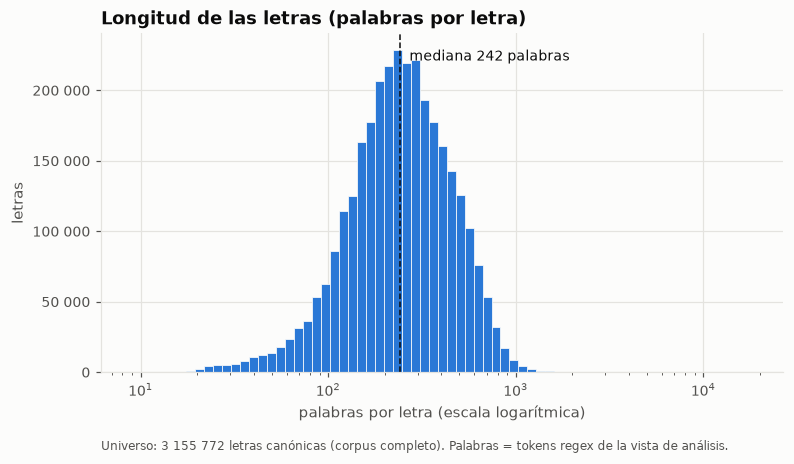

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(np.log10(max(nw.min(), 1)), np.log10(nw.max()), 70)
ax.hist(nw, bins=bins, color=viz.SEQUENTIAL, edgecolor=viz.SURFACE, linewidth=0.5)
ax.set_xscale("log")
med = np.median(nw)
ax.axvline(med, color=viz.TEXT, linewidth=1, linestyle="--")
ax.annotate(f"mediana {med:.0f} palabras", xy=(med, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", fontsize=9, color=viz.TEXT)
ax.set_title("Longitud de las letras (palabras por letra)")
ax.set_xlabel("palabras por letra (escala logarítmica)"); ax.set_ylabel("letras")
ax.yaxis.set_major_formatter(viz.thousands())
viz.caption(ax, f"Universo: {fmt(len(nw))} letras canónicas (corpus completo). Palabras = tokens regex de la vista de análisis.")
viz.save(fig, FIG / "e1_longitud_letras.png"); plt.show()

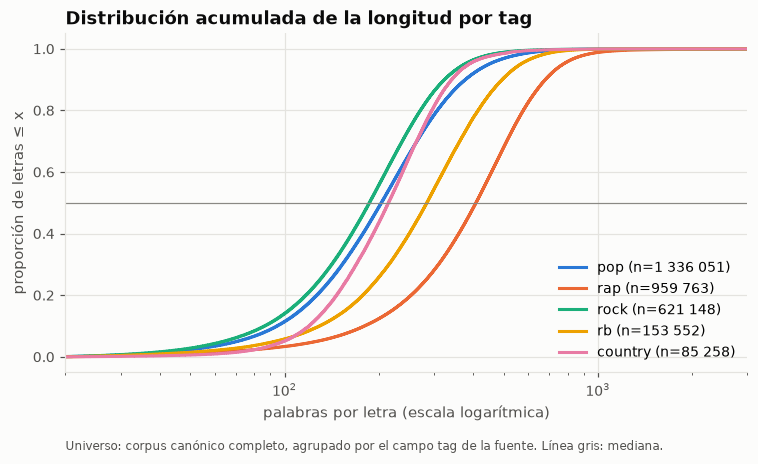

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
for tag in viz.TAG_ORDER:
    w = np.sort(meta.filter(pc.equal(meta["tag"], tag))["n_words"].to_numpy())
    y = np.arange(1, len(w) + 1) / len(w)
    ax.plot(w, y, color=viz.TAG_COLORS[tag], linewidth=2, label=f"{tag} (n={fmt(len(w))})")
ax.set_xscale("log"); ax.set_xlim(20, 3000)
ax.axhline(0.5, color=viz.MUTED, linewidth=0.8)
ax.set_title("Distribución acumulada de la longitud por tag")
ax.set_xlabel("palabras por letra (escala logarítmica)"); ax.set_ylabel("proporción de letras ≤ x")
ax.legend(loc="lower right")
viz.caption(ax, "Universo: corpus canónico completo, agrupado por el campo tag de la fuente. Línea gris: mediana.")
viz.save(fig, FIG / "e1_longitud_por_tag.png"); plt.show()

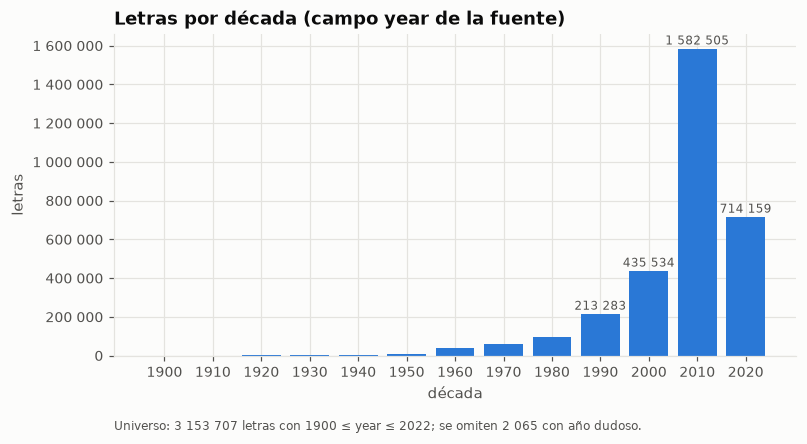

| década | letras |
|---|---|
| 1 900 | 100 |
| 1 910 | 182 |
| 1 920 | 1 361 |
| 1 930 | 1 096 |
| 1 940 | 1 200 |
| 1 950 | 9 014 |
| 1 960 | 39 341 |
| 1 970 | 62 259 |
| 1 980 | 93 673 |
| 1 990 | 213 283 |
| 2 000 | 435 534 |
| 2 010 | 1 582 505 |
| 2 020 | 714 159 |

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.8))
dec = (year // 10) * 10
valid = (year >= 1900) & (year <= 2022)
decs, cnt = np.unique(dec[valid], return_counts=True)
ax.bar([str(d) for d in decs], cnt, color=viz.SEQUENTIAL, width=0.8)
for x, c in zip(range(len(decs)), cnt):
    if c > cnt.max() * 0.08:
        ax.annotate(fmt(int(c)), xy=(x, c), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=viz.TEXT_SECONDARY)
ax.set_title("Letras por década (campo year de la fuente)")
ax.set_xlabel("década"); ax.set_ylabel("letras")
ax.yaxis.set_major_formatter(viz.thousands())
viz.caption(ax, f"Universo: {fmt(int(valid.sum()))} letras con 1900 ≤ year ≤ 2022; se omiten {fmt(int((~valid).sum()))} con año dudoso.")
viz.save(fig, FIG / "e1_letras_por_decada.png"); plt.show()
show([{"década": int(d), "letras": int(c)} for d, c in zip(decs, cnt)])

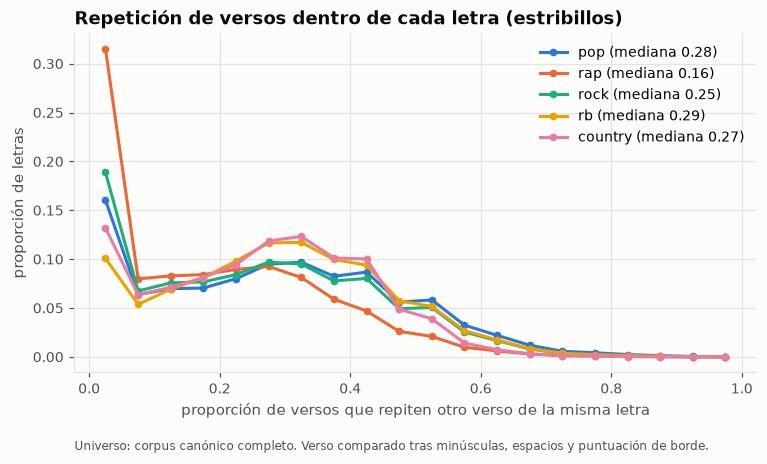

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
edges = np.linspace(0, 1, 21)
for tag in viz.TAG_ORDER:
    r = meta.filter(pc.equal(meta["tag"], tag))["repeated_line_share"].to_numpy()
    h, _ = np.histogram(r, bins=edges)
    ax.plot((edges[:-1] + edges[1:]) / 2, h / h.sum(), color=viz.TAG_COLORS[tag], marker="o", markersize=4,
            label=f"{tag} (mediana {np.median(r):.2f})")
ax.set_title("Repetición de versos dentro de cada letra (estribillos)")
ax.set_xlabel("proporción de versos que repiten otro verso de la misma letra"); ax.set_ylabel("proporción de letras")
ax.legend()
viz.caption(ax, "Universo: corpus canónico completo. Verso comparado tras minúsculas, espacios y puntuación de borde.")
viz.save(fig, FIG / "e1_repeticion_por_tag.png"); plt.show()

## 9. Hallazgos e interpretación

1. **El corpus es grande y casi completamente inglés tras una limpieza conservadora.** De
   3 179 588 registros, 3 177 443 (99,93 %) se aceptan; sólo 231 se excluyen y 1 914 quedan en
   revisión por desacuerdo entre detectores. Los excluidos por idioma son mayoritariamente
   japonés y chino (80 y 56). El dataset de origen ya estaba prefiltrado (longitud mínima de
   101 caracteres, sin columna de idioma), así que la limpieza consistió sobre todo en
   **normalizar formato**: un tercio de las letras (33,9 %) cambió en la vista estructural, casi
   siempre por apóstrofos tipográficos (23,2 %) o espacios Unicode como U+2005 (15,8 %).
   Sin esa normalización, `don't` y `don’t` serían tipos distintos en todas las estadísticas.

2. **Los detectores de idioma no son intercambiables.** La regla de acuerdo evitó excluir
   1 447 letras en las que lingua proponía otro idioma y py3langid inglés; los ejemplos
   inspeccionados (Daft Punk «Harder, Better…», letras con un verso en español o francés)
   son inglés o mezcla, no letras extranjeras. Las letras con varios idiomas quedan, por diseño,
   en revisión y no se reportan como inglés.

3. **Duplicados: pocos y con significado.** 21 671 registros (0,7 %) repiten exactamente una
   letra aceptada; el caso extremo (18 registros) es «Have Yourself a Merry Little Christmas»
   interpretada por artistas distintos. Es decir, la duplicación textual refleja **covers**, no
   errores de scraping; por eso la letra canónica es única pero el grupo de split los mantiene
   juntos, evitando que la misma letra aparezca en train y test.

4. **Distribución léxica de cola larga.** 902 M palabras y 1,28 M tipos; el 51,6 % de los tipos
   son *hapax* pero suponen sólo el 0,073 % de los tokens, y únicamente 57 027 tipos aparecen
   ≥ 100 veces. Esto anticipa (E2) una distribución tipo Zipf y justifica umbrales de frecuencia
   mínima en los vocabularios de TF-IDF/Word2Vec.

5. **Las letras son textos cortos y muy repetitivos.** Mediana de 242 palabras, 37 versos y
   6 estrofas; una letra típica repite el 24 % de sus versos. La repetición depende del género:
   el rap es el doble de largo (mediana 408 palabras) y el menos repetitivo (mediana 0,16; el
   31 % de las letras de rap casi no repite versos), mientras pop, rb y country rondan 0,27–0,29.
   Esta diferencia (verso narrativo frente a estribillo) es una sección comparable para E2–E4
   y advierte que las frecuencias de las letras pop están infladas por la repetición.

6. **El salto de línea no es una oración, pero sí una frontera necesaria.** En la muestra
   auditada (400 letras), la segmentación por defecto de spaCy produjo «oraciones» de 23
   palabras y el 64 % cruzaba al menos un verso, uniendo versos independientes; forzar la
   frontera en cada verso da unidades de ~6,5 palabras sin cruces. Se adopta la política por
   verso para POS/dependencias, documentando que algunas oraciones gramaticales reales sí
   continúan en el verso siguiente (encabalgamiento) y quedarán partidas.

7. **Limitaciones registradas.** (a) Los marcadores de hablante entre paréntesis, como
   `(mimi)`, no se eliminan porque no son distinguibles con seguridad de letra cantada entre
   paréntesis; (b) el campo `tag` es la etiqueta de la fuente, no un género verificado, y el
   corpus está desbalanceado (pop 42 %, country 2,7 %); (c) `year` tiene 2 065 valores dudosos
   (< 1900 o > 2022) y el 72,8 % de las letras son de 2010–2022, lo que limita los análisis
   diacrónicos de E5; (d) las estadísticas de segmentación de la sección 6 se calculan sobre la anotación
   spaCy completa (3 155 772 de 3 155 772 letras; la celda verifica la cobertura): mediana de
   37 versos, 40 oraciones y 6,5 palabras por oración por letra; hay más oraciones que versos
   porque el parser aún divide algunos versos largos en varias oraciones.